# DENTEX classification — SVM

The dataset is downloaded from Hugging Face using the same `keycxl/DENTEX` repository and ZIP extraction procedure as your original VotingClassifier notebook. No Google Drive dataset path is needed.\n\nThis notebook trains and evaluates **only SVM** for the three labelled DENTEX tasks:
1. Quadrant classification
2. Tooth enumeration
3. Abnormality classification

**Required experimental settings**
- `GroupShuffleSplit(test_size=0.30, random_state=42)` for the held-out test set.
- `StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)` for cross-validation.
- `GridSearchCV(scoring="f1_macro")`.
- Macro precision, recall and F1 for final evaluation.
- No SMOTE.
- Keep all teeth from one X-ray image in the same split/fold.

The feature pipeline uses the annotated tooth bounding boxes to crop teeth and extract HOG features. Therefore, this notebook evaluates classification of **given/annotated tooth crops**; it does not train a detector to find tooth boxes in a full panoramic image.


In [ ]:
# 1. Install packages and download DENTEX exactly as in the original VotingClassifier notebook

!pip install -q huggingface_hub opencv-python scikit-image scikit-learn pandas

import os, glob, json, zipfile, warnings
from collections import Counter

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import hog

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

from huggingface_hub import list_repo_files, hf_hub_download

# Same Hugging Face dataset repository and download method as your
# original VotingClassifier notebook.
REPO = "keycxl/DENTEX"

repo_files = list_repo_files(REPO, repo_type="dataset")
zip_files = [f for f in repo_files if f.endswith(".zip")]
print("Available ZIP files:", zip_files)

zip_name = [f for f in zip_files if f.endswith("training_data.zip")][0]
zip_path = hf_hub_download(
    REPO,
    zip_name,
    repo_type="dataset",
    local_dir="dentex_data"
)
print("Downloaded to:", zip_path)

# Extract into dentex_train, same as the original notebook.
if not os.path.exists("dentex_train"):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall("dentex_train")

print("Extraction completed.")
print("Extracted folders:", glob.glob("dentex_train/*"))


Available ZIP files: ['DENTEX/test_data.zip', 'DENTEX/training_data.zip', 'DENTEX/validation_data.zip']


DENTEX/training_data.zip: reconstructing file:   0%|          |  0.00B / 10.9GB            

DENTEX/training_data.zip: downloading bytes:           |  0.00B            

Downloaded to: /content/dentex_data/DENTEX/training_data.zip
Extraction completed.
Extracted folders: ['dentex_train/training_data']


## Data preparation
We load the JSON annotations, map category IDs to readable class names, and find the matching X-ray files.

In [ ]:
# 2. Locate the three annotation JSON files inside the downloaded dataset

jsons = glob.glob("dentex_train/**/*.json", recursive=True)

quad_matches = [p for p in jsons if p.endswith("train_quadrant.json")]
enum_matches = [p for p in jsons if p.endswith("train_quadrant_enumeration.json")]
disease_matches = [p for p in jsons if p.endswith("train_quadrant_enumeration_disease.json")]

assert quad_matches and enum_matches and disease_matches, (
    "Could not find all three JSON files. Check whether the ZIP was extracted correctly."
)

quad_json = quad_matches[0]
enum_json = enum_matches[0]
dis_json = disease_matches[0]

print(quad_json, enum_json, dis_json, sep="\\n")

for path in [quad_json, enum_json, dis_json]:
    with open(path, "r") as f:
        d = json.load(f)
    print("\\n", os.path.basename(path), "->", len(d["images"]), "images,", len(d["annotations"]), "annotations")
    print("Annotation keys:", list(d["annotations"][0].keys()))
    for key, value in d.items():
        if key.startswith("categories"):
            print(key, [c["name"] for c in value])


# 2. Read annotations and match each annotation to its X-ray image

def build_df(json_path, label_key, category_key):
    """Create one row per annotated tooth/object and find its image file."""
    with open(json_path, "r") as f:
        data = json.load(f)

    folder = os.path.dirname(json_path)
    image_paths = {}
    for path in glob.glob(os.path.join(folder, "**", "*"), recursive=True):
        if path.lower().endswith((".png", ".jpg", ".jpeg")):
            image_paths[os.path.basename(path)] = path

    categories = {c["id"]: str(c["name"]) for c in data[category_key]}
    images = {im["id"]: im for im in data["images"]}

    rows = []
    missing = 0
    for ann in data["annotations"]:
        im = images[ann["image_id"]]
        filename = im["file_name"]
        path = image_paths.get(os.path.basename(filename))
        if path is None:
            missing += 1
            continue
        label_id = ann[label_key]
        rows.append({
            "image_id": ann["image_id"],
            "file": filename,
            "image_path": path,
            "width": im["width"],
            "height": im["height"],
            "bbox": ann["bbox"],
            "label": label_id,
            "label_name": categories[label_id]
        })

    df = pd.DataFrame(rows).reset_index(drop=True)
    print(os.path.basename(json_path), "| rows:", len(df), "| missing image files:", missing)
    return df

# The JSON files use different category keys for the three tasks.
df_quad = build_df(quad_json, "category_id", "categories")
df_enum = build_df(enum_json, "category_id_2", "categories_2")
df_dis  = build_df(dis_json, "category_id_3", "categories_3")

for task_name, frame in [("Quadrant", df_quad), ("Enumeration", df_enum), ("Disease", df_dis)]:
    print("\\n", task_name, "class counts:")
    print(frame["label_name"].value_counts())


dentex_train/training_data/quadrant/train_quadrant.json\ndentex_train/training_data/quadrant_enumeration/train_quadrant_enumeration.json\ndentex_train/training_data/quadrant-enumeration-disease/train_quadrant_enumeration_disease.json
\n train_quadrant.json -> 693 images, 2772 annotations
Annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'category_id', 'id', 'area']
categories ['2', '1', '3', '4']
\n train_quadrant_enumeration.json -> 634 images, 18095 annotations
Annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'id', 'area', 'category_id_1', 'category_id_2']
categories_1 [1, 2, 3, 4]
categories_2 ['1', '2', '3', '4', '5', '6', '7', '8']
\n train_quadrant_enumeration_disease.json -> 705 images, 3529 annotations
Annotation keys: ['iscrowd', 'image_id', 'bbox', 'segmentation', 'id', 'area', 'category_id_1', 'category_id_2', 'category_id_3']
categories_1 ['1', '2', '3', '4']
categories_2 ['1', '2', '3', '4', '5', '6', '7', '8']
categories_3 ['Impacted', 'Cari

## Feature extraction
Each annotated bounding box is cropped, resized, enhanced, and converted into HOG features. The normalized box coordinates are appended.

In [ ]:
# 3. Convert each annotated tooth crop into numerical features

def extract_one_feature(row):
    image = cv2.imread(row["image_path"], cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Could not read image: {row['image_path']}")

    x, y, w, h = row["bbox"]  # COCO format: x, y, width, height
    x1, y1 = max(0, int(x)), max(0, int(y))
    x2 = min(image.shape[1], int(x + w))
    y2 = min(image.shape[0], int(y + h))
    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        crop = image  # defensive fallback for an invalid/empty box

    crop = cv2.resize(crop, (64, 64))
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    crop = clahe.apply(crop)

    hog_features = hog(
        crop, orientations=9, pixels_per_cell=(8, 8),
        cells_per_block=(2, 2), block_norm="L2-Hys",
        feature_vector=True
    )

    # Add normalized bounding-box location and size.
    box_features = np.array([
        x / row["width"], y / row["height"],
        w / row["width"], h / row["height"]
    ], dtype=float)

    return np.concatenate([hog_features, box_features])

def make_feature_matrix(df, task_name):
    X = np.vstack([extract_one_feature(row) for _, row in df.iterrows()])
    y = df["label_name"].astype(str).to_numpy()
    groups = df["image_id"].to_numpy()
    print(task_name, "| X shape:", X.shape, "| labels:", len(np.unique(y)),
          "| images:", len(np.unique(groups)))
    return X, y, groups

tasks = {
    "quadrant": {"df": df_quad},
    "enumeration": {"df": df_enum},
    "disease": {"df": df_dis}
}

for name, task in tasks.items():
    task["X"], task["y"], task["groups"] = make_feature_matrix(task["df"], name)


quadrant | X shape: (2772, 1768) | labels: 4 | images: 693
enumeration | X shape: (18095, 1768) | labels: 8 | images: 634
disease | X shape: (3529, 1768) | labels: 4 | images: 678


## Train/test split
We split by `image_id`, not by individual tooth, to avoid leakage between teeth from the same X-ray.

In [ ]:
# 4. Make a 70/30 image-grouped train/test split

for name, task in tasks.items():
    splitter = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
    train_idx, test_idx = next(
        splitter.split(task["X"], task["y"], groups=task["groups"])
    )

    task["X_train"], task["X_test"] = task["X"][train_idx], task["X"][test_idx]
    task["y_train"], task["y_test"] = task["y"][train_idx], task["y"][test_idx]
    task["groups_train"] = task["groups"][train_idx]
    task["groups_test"] = task["groups"][test_idx]

    train_images = set(task["groups_train"])
    test_images = set(task["groups_test"])
    overlap = train_images.intersection(test_images)

    print(f"\\n{name.upper()}")
    print("Training teeth:", len(train_idx), "| Testing teeth:", len(test_idx))
    print("Training images:", len(train_images), "| Testing images:", len(test_images))
    print("Images shared across train/test:", len(overlap))
    print("Training class counts:\\n", pd.Series(task["y_train"]).value_counts())
    print("Testing class counts:\\n", pd.Series(task["y_test"]).value_counts())
    assert len(overlap) == 0, "Data leakage: an image occurs in both splits!"

    # Check that all classes are present in training data.
    missing_train = set(task["y"]) - set(task["y_train"])
    if missing_train:
        warnings.warn(f"{name}: classes absent from training split: {missing_train}")


\nQUADRANT
Training teeth: 1940 | Testing teeth: 832
Training images: 485 | Testing images: 208
Images shared across train/test: 0
Training class counts:\n 2    485
1    485
3    485
4    485
Name: count, dtype: int64
Testing class counts:\n 1    208
2    208
3    208
4    208
Name: count, dtype: int64
\nENUMERATION
Training teeth: 12610 | Testing teeth: 5485
Training images: 443 | Testing images: 191
Images shared across train/test: 0
Training class counts:\n 3    1750
1    1748
2    1744
4    1684
7    1626
5    1601
6    1438
8    1019
Name: count, dtype: int64
Testing class counts:\n 1    760
2    753
3    749
4    720
5    698
7    688
6    632
8    485
Name: count, dtype: int64
\nDISEASE
Training teeth: 2468 | Testing teeth: 1061
Training images: 474 | Testing images: 204
Images shared across train/test: 0
Training class counts:\n Caries               1527
Impacted              434
Deep Caries           398
Periapical Lesion     109
Name: count, dtype: int64
Testing class counts:

In [ ]:
# 5. Cross-validation object
# Groups passed to GridSearchCV ensure that teeth from one X-ray stay together.
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)


## Model and hyperparameter tuning

In [ ]:
# 6. Define the SVM model and hyperparameter grid
# Scaling is important for SVM because HOG features and box features
# should be on comparable scales.
model = make_pipeline(
    StandardScaler(),
    SVC(class_weight="balanced")
)

param_grid = [
    {
        "svc__kernel": ["rbf"],
        "svc__C": [0.1, 1, 10],
        "svc__gamma": ["scale", 0.01]
    },
    {
        "svc__kernel": ["linear"],
        "svc__C": [0.1, 1, 10]
    }
]

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

# svm_model_enum = make_pipeline(
#     StandardScaler(),
#     LinearSVC(class_weight="balanced", random_state=42, max_iter=5000)
# )
# param_grid= {
#     "linearsvc__C": [0.1, 1, 10]
# }

\n======================================================================
GRID SEARCH: QUADRANT
Fitting 3 folds for each of 9 candidates, totalling 27 fits
\nBest parameters:
{'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
\nClassification report:
              precision    recall  f1-score   support

           1       0.99      1.00      0.99       208
           2       1.00      0.99      1.00       208
           3       1.00      1.00      1.00       208
           4       1.00      1.00      1.00       208

    accuracy                           1.00       832
   macro avg       1.00      1.00      1.00       832
weighted avg       1.00      1.00      1.00       832



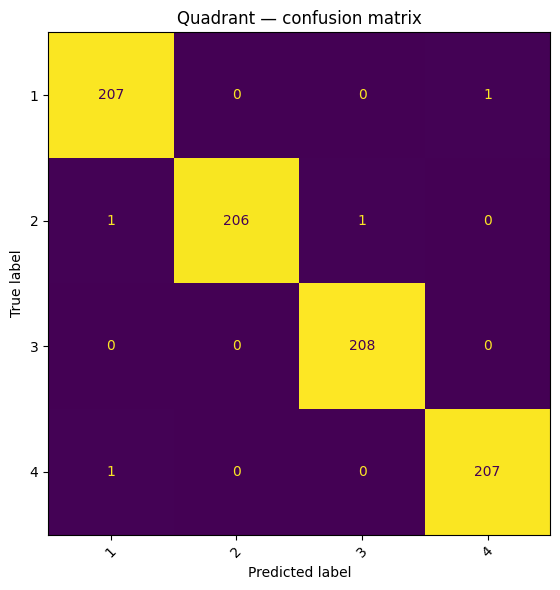

,task,best_cv_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,quadrant,0.990213,0.995192,0.99521,0.995192,0.995192


In [ ]:
# 7. Tune the model separately for each task and evaluate on the held-out test set

results = []
best_models = {}
best_parameters = {}
name="quadrant"
task=tasks[name]


print("\\n" + "=" * 70)
print("GRID SEARCH:", name.upper())
print("=" * 70)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(
    task["X_train"], task["y_train"],
    groups=task["groups_train"]
)

best_model = search.best_estimator_
y_pred = best_model.predict(task["X_test"])

precision = precision_score(task["y_test"], y_pred,
                            average="macro", zero_division=0)
recall = recall_score(task["y_test"], y_pred,
                      average="macro", zero_division=0)
f1 = f1_score(task["y_test"], y_pred,
              average="macro", zero_division=0)
accuracy = accuracy_score(task["y_test"], y_pred)

best_models[name] = best_model
best_parameters[name] = search.best_params_

results.append({
    "task": name,
    "best_cv_f1_macro": search.best_score_,
    "test_accuracy": accuracy,
    "test_precision_macro": precision,
    "test_recall_macro": recall,
    "test_f1_macro": f1
})

print("\\nBest parameters:")
print(search.best_params_)
print("\\nClassification report:")
print(classification_report(task["y_test"], y_pred, zero_division=0))

labels = sorted(np.unique(np.concatenate([task["y_test"], y_pred])))
cm = confusion_matrix(task["y_test"], y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title(f"{name.title()} — confusion matrix")
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
display(results_df)


\n======================================================================
GRID SEARCH: DISEASE
Fitting 3 folds for each of 9 candidates, totalling 27 fits
\nBest parameters:
{'svc__C': 1, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}
\nClassification report:
                   precision    recall  f1-score   support

           Caries       0.79      0.82      0.80       662
      Deep Caries       0.35      0.33      0.34       180
         Impacted       0.76      0.90      0.82       170
Periapical Lesion       0.50      0.02      0.04        49

         accuracy                           0.71      1061
        macro avg       0.60      0.52      0.50      1061
     weighted avg       0.70      0.71      0.69      1061



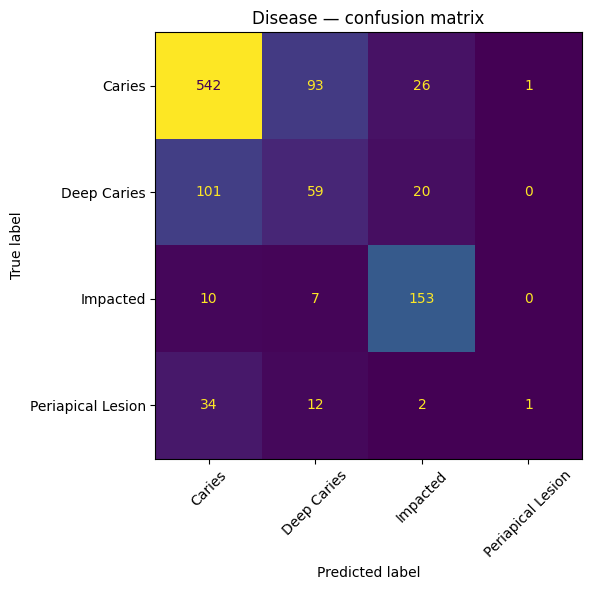

,task,best_cv_f1_macro,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,quadrant,0.990213,0.995192,0.99521,0.995192,0.995192
1,disease,0.495235,0.711593,0.59879,0.516729,0.500939


In [ ]:
name="disease"
task=tasks[name]


print("\\n" + "=" * 70)
print("GRID SEARCH:", name.upper())
print("=" * 70)

search = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    refit=True
)

search.fit(
    task["X_train"], task["y_train"],
    groups=task["groups_train"]
)

best_model = search.best_estimator_
y_pred = best_model.predict(task["X_test"])

precision = precision_score(task["y_test"], y_pred,
                            average="macro", zero_division=0)
recall = recall_score(task["y_test"], y_pred,
                      average="macro", zero_division=0)
f1 = f1_score(task["y_test"], y_pred,
              average="macro", zero_division=0)
accuracy = accuracy_score(task["y_test"], y_pred)

best_models[name] = best_model
best_parameters[name] = search.best_params_

results.append({
    "task": name,
    "best_cv_f1_macro": search.best_score_,
    "test_accuracy": accuracy,
    "test_precision_macro": precision,
    "test_recall_macro": recall,
    "test_f1_macro": f1
})

print("\\nBest parameters:")
print(search.best_params_)
print("\\nClassification report:")
print(classification_report(task["y_test"], y_pred, zero_division=0))

labels = sorted(np.unique(np.concatenate([task["y_test"], y_pred])))
cm = confusion_matrix(task["y_test"], y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title(f"{name.title()} — confusion matrix")
plt.tight_layout()
plt.show()

results_df = pd.DataFrame(results)
display(results_df)


In [ ]:
# 8. Save the results and best hyperparameters for the Voting Classifier work

params_rows = []
for task_name, params in best_parameters.items():
    row = {"task": task_name}
    row.update(params)
    params_rows.append(row)

params_df = pd.DataFrame(params_rows)
display(params_df)

results_df.to_csv("SVM_results.csv", index=False)
params_df.to_csv("SVM_best_parameters.csv", index=False)

print("Saved: SVM_results.csv")
print("Saved: SVM_best_parameters.csv")

,task,svc__C,svc__gamma,svc__kernel
0,quadrant,1,scale,rbf
1,disease,1,scale,rbf


Saved: SVM_results.csv
Saved: SVM_best_parameters.csv


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

svm_model_enum = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)

svm_param_grid_enum = {
    "linearsvc__C": [0.1, 1, 10]
}

In [ ]:
best_svm_enum = svm_search_enum.best_estimator_

y_pred = best_svm_enum.predict(task["X_test"])

print("Best parameters:", svm_search_enum.best_params_)
print("CV F1:", svm_search_enum.best_score_)

print(classification_report(
    task["y_test"],
    y_pred,
    zero_division=0
))

In [ ]:
print(task["X_train"].shape)
print(task["y_train"].shape)
print(cv)


(12610, 1768)
(12610,)
StratifiedGroupKFold(n_splits=3, random_state=42, shuffle=True)


In [ ]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.model_selection import GridSearchCV

svm_model_enum = make_pipeline(
    StandardScaler(),
    LinearSVC(
        class_weight="balanced",
        random_state=42,
        max_iter=2000,
        dual="auto",
        tol=1e-3
    )
)

svm_param_grid_enum = {
    "linearsvc__C": [0.1, 1]
}

task = tasks["enumeration"]

svm_search_enum = GridSearchCV(
    estimator=svm_model_enum,
    param_grid=svm_param_grid_enum,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    verbose=2,
    refit=True
)

svm_search_enum.fit(
    task["X_train"],
    task["y_train"],
    groups=task["groups_train"]
)

print("Best Parameters:", svm_search_enum.best_params_)
print("Best Macro F1:", svm_search_enum.best_score_)


Fitting 3 folds for each of 2 candidates, totalling 6 fits
Best Parameters: {'linearsvc__C': 0.1}
Best Macro F1: 0.4977571111587263


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

task = tasks["enumeration"]

# Predict using already trained model
y_pred_enum = svm_search_enum.predict(task["X_test"])

# Evaluation scores
print("Best Parameters:", svm_search_enum.best_params_)
print("Best CV Macro F1:", svm_search_enum.best_score_)

print("\nAccuracy:", accuracy_score(task["y_test"], y_pred_enum))

print("Precision:", precision_score(
    task["y_test"], y_pred_enum,
    average="macro", zero_division=0
))

print("Recall:", recall_score(
    task["y_test"], y_pred_enum,
    average="macro", zero_division=0
))

print("F1 Macro:", f1_score(
    task["y_test"], y_pred_enum,
    average="macro", zero_division=0
))

# Classification report
print("\nClassification Report:")
print(classification_report(
    task["y_test"], y_pred_enum,
    zero_division=0
))

# Confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(task["y_test"], y_pred_enum))


Best Parameters: {'linearsvc__C': 0.1}
Best CV Macro F1: 0.4977571111587263

Accuracy: 0.5126709206927985
Precision: 0.5133884740008866
Recall: 0.5173106675273069
F1 Macro: 0.5146336924648867

Classification Report:
              precision    recall  f1-score   support

           1       0.52      0.57      0.55       760
           2       0.46      0.45      0.46       753
           3       0.55      0.59      0.57       749
           4       0.46      0.42      0.44       720
           5       0.46      0.40      0.43       698
           6       0.54      0.55      0.55       632
           7       0.53      0.52      0.52       688
           8       0.59      0.63      0.61       485

    accuracy                           0.51      5485
   macro avg       0.51      0.52      0.51      5485
weighted avg       0.51      0.51      0.51      5485


Confusion Matrix:
[[433 193  50  29  22  12  12   9]
 [190 341 107  38  44  11   9  13]
 [ 62  91 442  72  46  14  12  10]
 [ 61  42